<a href="https://colab.research.google.com/github/soniatik21-crypto/audio-project/blob/main/audio-project%202.0.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [1]:
# === УСТАНОВКА ВСЕХ БИБЛИОТЕК ===
!pip install silero-vad
!pip install noisereduce
!pip install librosa
!pip install soundfile
!pip install ffmpeg-python
!apt-get install ffmpeg -y

print("✅ Все библиотеки установлены!")


   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 7.2/7.2 MB 34.7 MB/s  0:00:00
Reading package lists... Done
Building dependency tree... Done
Reading state information... Done
ffmpeg is already the newest version (7:6.1.1-3ubuntu5).
0 upgraded, 0 newly installed, 0 to remove and 0 not upgraded.
✅ Все библиотеки установлены!


In [2]:
# === Конвертация видео в аудио (ffmpeg) ===
from google.colab import files
import os

# 1) Загружаем видео с айфона
uploaded = files.upload()
video_file = list(uploaded.keys())[0]
print("🎬 Загружено видео:", video_file)

# 2) Извлекаем аудио (оборачиваем имя в кавычки!)
audio_out = "audio_from_video.wav"
!ffmpeg -i "{video_file}" -vn -acodec pcm_s16le -ar 16000 -ac 1 "{audio_out}"

# 3) Проверяем результат
if os.path.exists(audio_out):
    size = os.path.getsize(audio_out)
    print(f"✅ Готово! Аудио извлечено: {audio_out} ({size} байт)")
    files.download(audio_out)
else:
    print("❌ Ошибка конвертации")


Saving ScreenRecording_11-24-2026 22-07-36_1.mp4 to ScreenRecording_11-24-2026 22-07-36_1.mp4
🎬 Загружено видео: ScreenRecording_11-24-2026 22-07-36_1.mp4
ffmpeg version 6.1.1-3ubuntu5 Copyright (c) 2000-2023 the FFmpeg developers
  built with gcc 13 (Ubuntu 13.2.0-23ubuntu3)
  configuration: --prefix=/usr --extra-version=3ubuntu5 --toolchain=hardened --libdir=/usr/lib/x86_64-linux-gnu --incdir=/usr/include/x86_64-linux-gnu --arch=amd64 --enable-gpl --disable-stripping --disable-omx --enable-gnutls --enable-libaom --enable-libass --enable-libbs2b --enable-libcaca --enable-libcdio --enable-libcodec2 --enable-libdav1d --enable-libflite --enable-libfontconfig --enable-libfreetype --enable-libfribidi --enable-libglslang --enable-libgme --enable-libgsm --enable-libharfbuzz --enable-libmp3lame --enable-libmysofa --enable-libopenjpeg --enable-libopenmpt --enable-libopus --enable-librubberband --enable-libshine --enable-libsnappy --enable-libsoxr --enable-libspeex --enable-libtheora --enable-l

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

In [3]:
from google.colab import files

# Загрузи файл с телефона
uploaded = files.upload()

print("✅ Файл загружен!")


Saving Динамика-к-1.wav to Динамика-к-1.wav
✅ Файл загружен!


In [4]:
import torch
import torchaudio
from silero_vad import load_silero_vad, read_audio, get_speech_timestamps

# Загружаем модель Silero VAD
model = load_silero_vad()

# Читаем аудиофайл (замени 'твой_файл.wav' на имя загруженного файла)
wav = read_audio('Динамика-к-1.wav')  # <-- впиши имя своего файла!

# Находим участки с речью
speech_timestamps = get_speech_timestamps(wav, model, sampling_rate=16000)

if speech_timestamps:
    print(f"✅ Голос найден! Обнаружено {len(speech_timestamps)} участков речи")
    for i, ts in enumerate(speech_timestamps):
        print(f"  Участок {i+1}: с {ts['start']/16000:.1f} сек по {ts['end']/16000:.1f} сек")
else:
    print("❌ Голос не обнаружен")


/usr/local/lib/python3.13/dist-packages/torch/jit/_serialization.py:176: FutureWarning: `torch.jit.load` is deprecated. Please switch to `torch.export`.
  warnings.warn(


✅ Голос найден! Обнаружено 4 участков речи
  Участок 1: с 0.5 сек по 2.8 сек
  Участок 2: с 3.0 сек по 4.8 сек
  Участок 3: с 4.9 сек по 7.1 сек
  Участок 4: с 7.2 сек по 7.5 сек


In [5]:
import numpy as np
import noisereduce as nr
import soundfile as sf

# Загружаем аудио
data, rate = sf.read('Динамика-к-1.wav')  # <-- имя файла!

# Убираем шум
reduced_noise = nr.reduce_noise(y=data, sr=rate)

# Сохраняем чистый файл
sf.write('clean_audio.wav', reduced_noise, rate)

print("✅ Шум убран! Файл сохранён как 'clean_audio.wav'")

# Скачиваем результат на телефон
files.download('clean_audio.wav')


✅ Шум убран! Файл сохранён как 'clean_audio.wav'


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

/tmp/ipykernel_1553/3850545342.py:14: UserWarning: amplitude_to_db was called on complex input so phase information will be discarded. To suppress this warning, call amplitude_to_db(np.abs(S)) instead.
  librosa.amplitude_to_db(librosa.stft(y), ref=np.max),


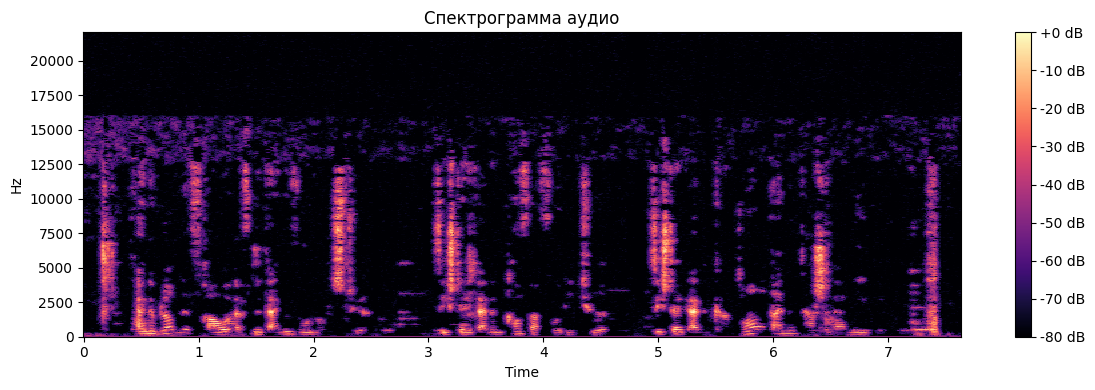

✅ Спектрограмма готова!


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

In [6]:
import librosa
import librosa.display
import matplotlib.pyplot as plt
import numpy as np

# Загружаем аудио
y, sr = librosa.load('clean_audio.wav', sr=None)  # или твой исходный файл

# Создаём картинку
plt.figure(figsize=(12, 4))

# Рисуем спектрограмму
librosa.display.specshow(
    librosa.amplitude_to_db(librosa.stft(y), ref=np.max),
    sr=sr,
    x_axis='time',
    y_axis='hz'
)

plt.colorbar(format='%+2.0f dB')
plt.title('Спектрограмма аудио')
plt.tight_layout()

# Показываем и сохраняем
plt.savefig('spectrogram.png')
plt.show()

print("✅ Спектрограмма готова!")
files.download('spectrogram.png')
